In [22]:
%load_ext autoreload
%autoreload 2

import os
import sys
import random
import subprocess
import re

sys.path.append(os.path.realpath('..'))

import numpy as np
import torch
import torchaudio
import pandas as pd

from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralClustering, DBSCAN
from matplotlib import pyplot as plt
import matplotlib.colors as mcolors
import IPython.display as ipd

from ResNetSE34V2 import MainModel
from LoadModel import load_model
from common import download_dataset, extract_dataset

from lab3.exercises_blank import ResNet, MainModel
from lab3.exercises_blank import test_dataset_loader as tdl
from lab3.ResNetBlocks import BasicBlock
from lab3.LossFunction import AAMSoftmaxLoss
from lab3.Optimizer import SGDOptimizer
from lab3.Scheduler import OneCycleLRScheduler
from lab3.load_save_pth import loadParameters
import torch.nn as nn

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
BASE_PATH = '/mnt/storage/work_dir/databases'

SAMPLE_RATE = 16000
WINDOW_SEC  = 2.0
STEP_SEC    = 0.5

CLUSTER_ALGO = 'agglo'
N_SPEAKERS   = 3
DBSCAN_EPS   = 0.6
DBSCAN_MIN_SAMPLES = 5

SYNTH_OUTPUT = 'synth_audio_example/synth_audio.wav'
TURN_SEC = 3.0
N_TURNS_PER_SPK = 3

In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', device)

spk_model = MainModel(nOut=512, encoder_type='ASP', n_mels=64, log_input=True)

with open('../data/lists/models.txt', 'r') as f:
    lines = f.readlines()

spk_model = load_model(spk_model, lines, save_path='../data/models')
spk_model.to(device)
spk_model.eval();

Using device: cuda
Embedding size is 512, encoder ASP.
File baseline_v2_ap.model is downloaded.


In [4]:
def list_voxceleb_utts(base_path):
    spk2utts = {}
    for spk in os.listdir(base_path):
        spk_dir = os.path.join(base_path, spk)
        if not os.path.isdir(spk_dir):
            continue
        files = []
        for root, _, fnames in os.walk(spk_dir):
            for fn in fnames:
                if fn.endswith('.wav'):
                    files.append(os.path.join(root, fn))
        if len(files) > 0:
            spk2utts[spk] = files
    return spk2utts


def make_synthetic_audio(spk2utts, n_speakers, n_turns_per_spk, turn_sec,
                         out_wav, seed=42):
    random.seed(seed)
    chosen_spks = random.sample(list(spk2utts.keys()), n_speakers)
    turns, labels = [], []
    sil = torch.zeros(int(0.2*SAMPLE_RATE))
    for _ in range(n_turns_per_spk):
        for lab, spk in enumerate(chosen_spks):
            utt_path = random.choice(spk2utts[spk])
            wav, sr = torchaudio.load(utt_path)
            if sr != SAMPLE_RATE:
                wav = torchaudio.functional.resample(wav, sr, SAMPLE_RATE)
            wav = wav.mean(dim=0, keepdim=False)
            L = int(turn_sec * SAMPLE_RATE)
            if wav.numel() < L:
                reps = int(np.ceil(L/wav.numel()))
                wav = wav.tile(reps)[:L]
            else:
                st = random.randint(0, wav.numel() - L)
                wav = wav[st:st + L]
            turns.append(wav); labels.append(lab)
            turns.append(sil);  labels.append(-1)

    mixture = torch.cat(turns)
    t = 0
    segments_ref = []
    for idx, seg in enumerate(turns):
        dur = seg.numel()/SAMPLE_RATE
        if labels[idx] >= 0:
            segments_ref.append((t, t + dur, labels[idx]))
        t += dur

    os.makedirs(os.path.dirname(out_wav), exist_ok=True)
    torchaudio.save(out_wav, mixture.unsqueeze(0), SAMPLE_RATE)

    rec_id = os.path.splitext(os.path.basename(out_wav))[0]
    ref_rttm = out_wav.replace('.wav', '_ref.rttm')
    rttm_lines = []
    for s, e, lab in segments_ref:
        dur = max(0.0, e - s)
        rttm_lines.append(f'SPEAKER {rec_id} 1 {s:.3f} {dur:.3f} <NA> <NA> speaker_{lab} <NA> <NA>')
    with open(ref_rttm, 'w') as f:
        f.write('\n'.join(rttm_lines))

    return out_wav, ref_rttm, chosen_spks, segments_ref


def run_clustering(X, cluster_algo, n_speakers, dbscan_eps, dbscan_min_samples,
                   agglo_linkage='average', agglo_metric='cosine',
                   spectral_affinity='nearest_neighbors'):
    if cluster_algo == 'kmeans':
        labels = KMeans(n_clusters=n_speakers, random_state=0).fit_predict(X)
    elif cluster_algo == 'agglo':
        try:
            labels = AgglomerativeClustering(n_clusters=n_speakers, linkage=agglo_linkage, metric=agglo_metric).fit_predict(X)
        except TypeError:
            labels = AgglomerativeClustering(n_clusters=n_speakers, linkage=agglo_linkage, affinity=agglo_metric).fit_predict(X)
    elif cluster_algo == 'spectral':
        labels = SpectralClustering(n_clusters=n_speakers, assign_labels='kmeans',
                                    random_state=0, affinity=spectral_affinity).fit_predict(X)
    elif cluster_algo == 'dbscan':
        labels = DBSCAN(eps=dbscan_eps, min_samples=dbscan_min_samples, metric='cosine').fit_predict(X)
    else:
        raise ValueError('Unknown cluster_algo')
    return labels


def merge_labels_to_segments(labels, starts, win_len, sr):
    segs = []
    if len(labels) == 0:
        return segs
    cur_lab = int(labels[0])
    cur_start = starts[0]
    for i in range(1, len(labels)):
        if int(labels[i]) != cur_lab:
            segs.append((cur_start/sr, (starts[i-1] + win_len)/sr, cur_lab))
            cur_lab = int(labels[i])
            cur_start = starts[i]
    segs.append((cur_start/sr, (starts[-1] + win_len)/sr, cur_lab))
    for idx in range(len(segs) - 1):
        segs[idx], segs[idx+1] = (segs[idx][0], (segs[idx][1] + segs[idx+1][0])/2, segs[idx][2]), \
                                 ((segs[idx][1] + segs[idx+1][0])/2, segs[idx+1][1], segs[idx+1][2])
    return segs


def write_rttm(segments, rec_id, out_path):
    rttm_lines = []
    for s, e, lab in segments:
        dur = max(0.0, e - s)
        rttm_lines.append(f'SPEAKER {rec_id} 1 {s:.3f} {dur:.3f} <NA> <NA> speaker_{lab} <NA> <NA>')
    with open(out_path, 'w') as f:
        f.write('\n'.join(rttm_lines))


def compute_der(ref_rttm, hyp_rttm):
    out = subprocess.run(
        ['python', 'score.py', '-r', ref_rttm, '-s', hyp_rttm],
        capture_output=True, text=True
    ).stdout
    for line in out.splitlines():
        if 'OVERALL' in line:
            m = re.search(r'([\d.]+)\s*$', line.strip())
            if m:
                return float(m.group(1))
    return None

In [5]:
base_path = f'{BASE_PATH}/voxceleb1_test/wav'
spk2utts = list_voxceleb_utts(base_path)
assert len(spk2utts) >= 2

AUDIO_PATH, REF_RTTM, chosen_spks, segments_ref = make_synthetic_audio(
    spk2utts,
    n_speakers=N_SPEAKERS, n_turns_per_spk=N_TURNS_PER_SPK,
    turn_sec=TURN_SEC, out_wav=SYNTH_OUTPUT, seed=42,
)

print('Chosen speakers:', chosen_spks)
print('Audio:', AUDIO_PATH)
print('Ref:', REF_RTTM)

Chosen speakers: ['id10284', 'id10279', 'id10286']
Audio: synth_audio_example/synth_audio.wav
Ref: synth_audio_example/synth_audio_ref.rttm


In [6]:
def run_diarization(audio_path, ref_rttm, spk_model,
                    window_sec=WINDOW_SEC, step_sec=STEP_SEC,
                    cluster_algo=CLUSTER_ALGO, n_speakers=N_SPEAKERS,
                    dbscan_eps=DBSCAN_EPS, dbscan_min_samples=DBSCAN_MIN_SAMPLES,
                    agglo_linkage='average', agglo_metric='cosine',
                    spectral_affinity='nearest_neighbors',
                    device=device, batch_size=64):
    wav, sr = torchaudio.load(audio_path)
    assert sr == SAMPLE_RATE
    if wav.size(0) > 1:
        wav = torch.mean(wav, dim=0, keepdim=True)
    wav = wav.squeeze(0)
    wav = wav/(wav.abs().max() + 1e-9)

    win_len = int(window_sec * SAMPLE_RATE)
    step    = int(step_sec   * SAMPLE_RATE)
    frames, starts = [], []
    for start in range(0, max(1, len(wav) - win_len + 1), step):
        end = start + win_len
        if end > len(wav):
            chunk = torch.zeros(win_len)
            chunk[:len(wav) - start] = wav[start:]
        else:
            chunk = wav[start:end]
        frames.append(chunk.unsqueeze(0))
        starts.append(start)
    frames = torch.stack(frames, dim=0)

    embeds = []
    with torch.no_grad():
        for i in range(0, len(frames), batch_size):
            batch = frames[i:i + batch_size].to(device).squeeze(1)
            embeds.append(spk_model(batch).cpu())
    embeds = torch.cat(embeds, dim=0).numpy()

    # кластеризация
    labels = run_clustering(embeds, cluster_algo, n_speakers,
                            dbscan_eps, dbscan_min_samples,
                            agglo_linkage, agglo_metric, spectral_affinity)

    segments_hyp = merge_labels_to_segments(labels, starts, win_len, SAMPLE_RATE)
    rec_id = os.path.splitext(os.path.basename(audio_path))[0]
    hyp_rttm = audio_path.replace('.wav', '_hyp.rttm')
    write_rttm(segments_hyp, rec_id, hyp_rttm)

    der = compute_der(ref_rttm, hyp_rttm)

    return {
        'der': der,
        'n_frames': len(starts),
        'n_clusters': len(set(labels.tolist())),
        'window_sec': window_sec,
        'step_sec': step_sec,
        'cluster_algo': cluster_algo,
        'n_speakers': n_speakers,
    }, segments_hyp, wav

# 1. Запуск алгоритма с настройками по умолчанию.

Baseline DER, %: 16.67
Frames: 54 | Clusters: 3


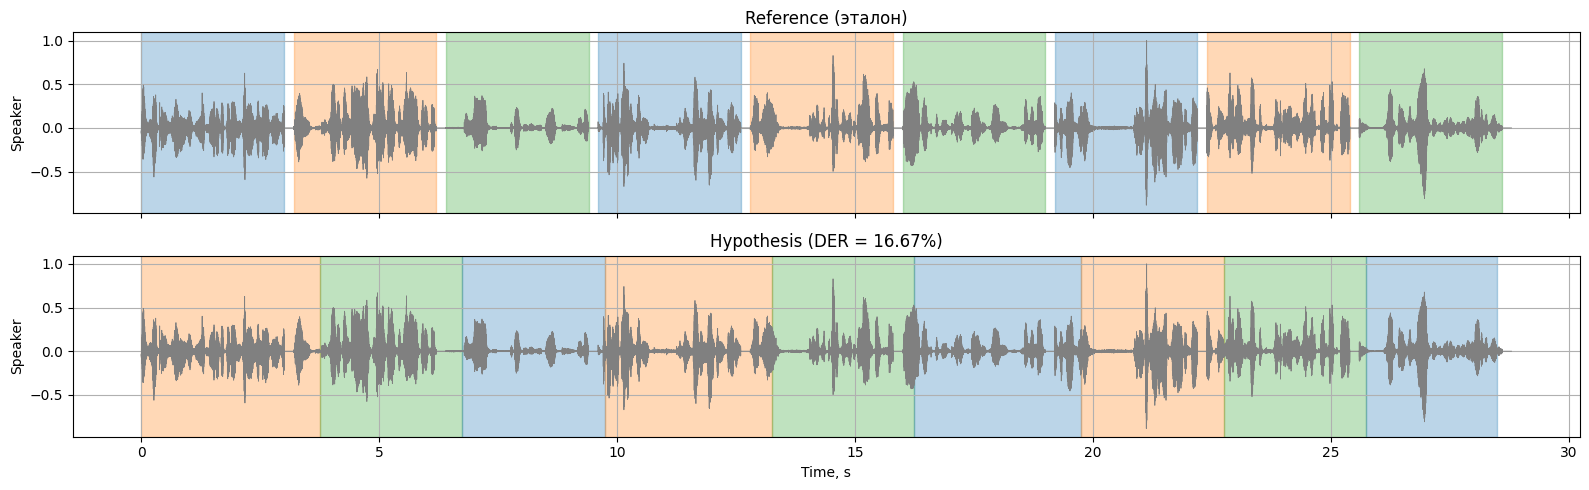

In [7]:
m1, segs_hyp1, wav1 = run_diarization(AUDIO_PATH, REF_RTTM, spk_model)
print('Baseline DER, %:', round(m1['der'], 2))
print('Frames:', m1['n_frames'], '| Clusters:', m1['n_clusters'])

times = np.arange(len(wav1)) / SAMPLE_RATE
colors = {idx: item for idx, item in enumerate(mcolors.TABLEAU_COLORS)}

fig, axes = plt.subplots(2, 1, figsize=(16, 5), sharex=True)

# Верхний — эталон
axes[0].plot(times, wav1.numpy(), color='gray', linewidth=0.6)
for s, e, lab in segments_ref:
    axes[0].axvspan(s, e, color=colors.get(lab), alpha=0.3)
axes[0].set_title('Reference (эталон)')
axes[0].set_ylabel('Speaker')
axes[0].grid(True)

# Нижний — гипотеза
axes[1].plot(times, wav1.numpy(), color='gray', linewidth=0.6)
for s, e, lab in segs_hyp1:
    axes[1].axvspan(s, e, color=colors.get(lab), alpha=0.3)
axes[1].set_title(f'Hypothesis (DER = {m1["der"]:.2f}%)')
axes[1].set_xlabel('Time, s')
axes[1].set_ylabel('Speaker')
axes[1].grid(True)

plt.tight_layout()
plt.show()

- Baseline-запуск с настройками по умолчанию DER = 16.67%.
- Получено 54 окна и 3 кластера. Число кластеров совпало с истинным (3 диктора).
- Ошибка 16.67% в основном связана с путаницей на границах сегментов.

# 2. Влияние размера оконной функции и её сдвига

DER, % (rows=window, cols=step):
step_sec     0.25   0.50   1.00
window_sec                     
0.5         13.80    NaN    NaN
1.0          7.41   9.81    NaN
1.5         11.67   8.89  10.00
2.0         13.89  16.67  13.33
2.5         20.56  18.52  14.26
3.0         15.00  18.52  22.22


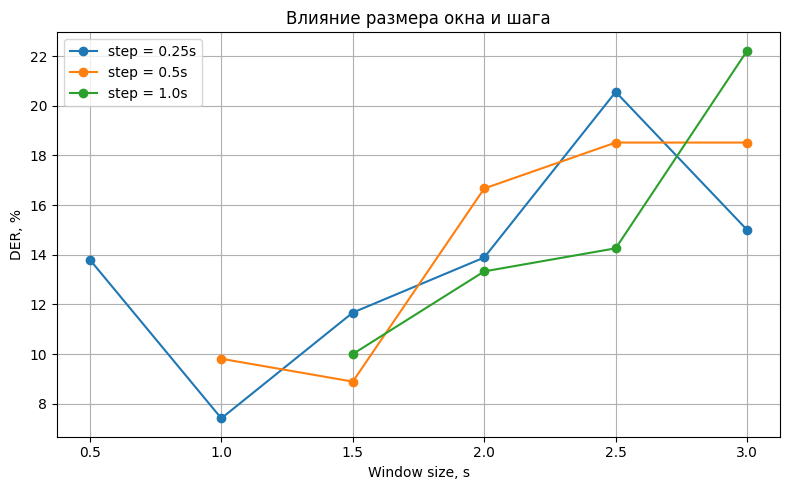

In [8]:
windows = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
steps   = [0.25, 0.5, 1.0]

rows = []
for w in windows:
    for s in steps:
        if s >= w:
            continue
        m, _, _ = run_diarization(AUDIO_PATH, REF_RTTM, spk_model,
                                  window_sec=w, step_sec=s)
        rows.append(m)

df_win = pd.DataFrame(rows)
pivot_der = df_win.pivot(index='window_sec', columns='step_sec', values='der')
print('DER, % (rows=window, cols=step):')
print(pivot_der.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
for s in sorted(df_win['step_sec'].unique()):
    sub = df_win[df_win['step_sec'] == s].sort_values('window_sec')
    ax.plot(sub['window_sec'], sub['der'], marker='o', label=f'step = {s}s')
ax.set_xlabel('Window size, s')
ax.set_ylabel('DER, %')
ax.set_title('Влияние размера окна и шага')
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

# 3 Влияние количества дикторов в синтезированной звукозаписи

                   mean   std
n_speakers_synth             
2                 14.67  2.01
3                 13.15  0.93
4                 12.89  1.52
5                 13.53  1.50
6                 13.67  1.51


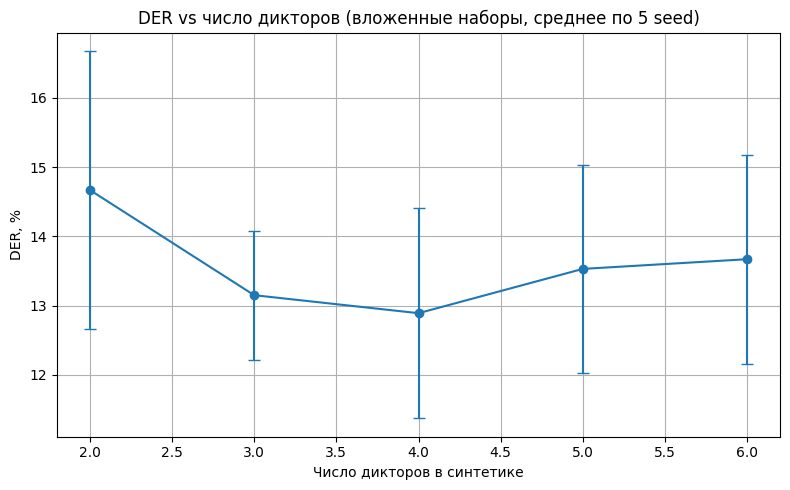

In [9]:
n_list = [2, 3, 4, 5, 6]
seeds  = [42, 1, 2, 3, 4]

random.seed(42)
all_spks_shuffled = random.sample(list(spk2utts.keys()), len(spk2utts))

rows_spk = []
for n in n_list:
    for sd in seeds:
        spk2utts_n = {spk: spk2utts[spk] for spk in all_spks_shuffled[:n]}

        out_wav = f'synth_audio_example/synth_{n}spk_seed{sd}.wav'
        wav_n, ref_n, _, _ = make_synthetic_audio(
            spk2utts_n,
            n_speakers=n, n_turns_per_spk=N_TURNS_PER_SPK,
            turn_sec=TURN_SEC, out_wav=out_wav, seed=sd,
        )
        m, _, _ = run_diarization(
            wav_n, ref_n, spk_model,
            window_sec=WINDOW_SEC, step_sec=STEP_SEC,
            cluster_algo=CLUSTER_ALGO, n_speakers=n,
        )
        m['n_speakers_synth'] = n
        m['seed'] = sd
        rows_spk.append(m)

df_spk = pd.DataFrame(rows_spk)

agg = df_spk.groupby('n_speakers_synth')['der'].agg(['mean', 'std']).round(2)
print(agg)

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(agg.index, agg['mean'], yerr=agg['std'], marker='o', capsize=4)
ax.set_xlabel('Число дикторов в синтетике')
ax.set_ylabel('DER, %')
ax.set_title('DER vs число дикторов (вложенные наборы, среднее по 5 seed)')
ax.grid(True)
plt.tight_layout()
plt.show()

- Модель практически инвариантна к количеству дикторов: DER 13–15% для 2-6 говорящих.
- Число говорящих не так важно как качество эмбеддингов и параметры окна.

# 4. Влияние алгоритмов кластеризации и их настроек

/home/ext-ivanova-mk@ad.speechpro.com/work_dir/srlab_venv/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/home/ext-ivanova-mk@ad.speechpro.com/work_dir/srlab_venv/lib/python3.8/site-packages/sklearn/manifold/_spectral_embedding.py:273: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


    config_name   der  n_clusters
         kmeans 11.85           3
   spectral_knn 13.15           3
 agglo_ward_euc 15.56           3
 agglo_comp_cos 15.56           3
  agglo_avg_euc 16.30           3
  agglo_avg_cos 16.67           3
 dbscan_e0.4_m5 33.15           6
   spectral_rbf 60.19           3
dbscan_e0.04_m5 72.59           1
 dbscan_e0.1_m5 72.59           1
 dbscan_e0.7_m5 72.59           1
 dbscan_e0.8_m5 72.59           1


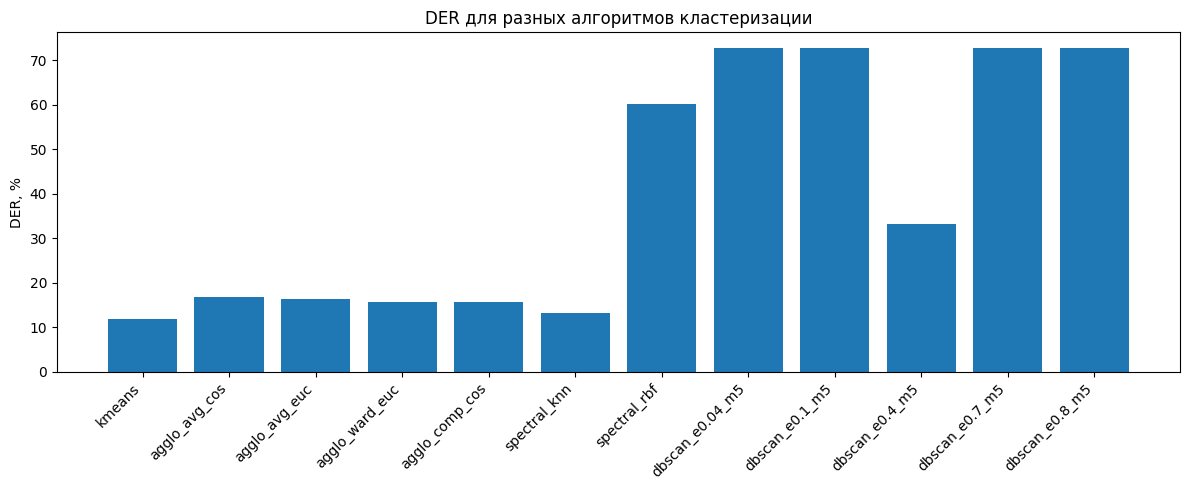

In [18]:
configs = [
    ('kmeans',              dict(cluster_algo='kmeans')),
    ('agglo_avg_cos',       dict(cluster_algo='agglo', agglo_linkage='average', agglo_metric='cosine')),
    ('agglo_avg_euc',       dict(cluster_algo='agglo', agglo_linkage='average', agglo_metric='euclidean')),
    ('agglo_ward_euc',      dict(cluster_algo='agglo', agglo_linkage='ward',    agglo_metric='euclidean')),
    ('agglo_comp_cos',      dict(cluster_algo='agglo', agglo_linkage='complete', agglo_metric='cosine')),
    ('spectral_knn',        dict(cluster_algo='spectral', spectral_affinity='nearest_neighbors')),
    ('spectral_rbf',        dict(cluster_algo='spectral', spectral_affinity='rbf')),
    ('dbscan_e0.04_m5',      dict(cluster_algo='dbscan', dbscan_eps=0.04, dbscan_min_samples=5)),
    ('dbscan_e0.1_m5',      dict(cluster_algo='dbscan', dbscan_eps=0.1, dbscan_min_samples=5)),
    ('dbscan_e0.4_m5',      dict(cluster_algo='dbscan', dbscan_eps=0.4, dbscan_min_samples=5)),
    ('dbscan_e0.7_m5',      dict(cluster_algo='dbscan', dbscan_eps=0.7, dbscan_min_samples=5)),
    ('dbscan_e0.8_m5',      dict(cluster_algo='dbscan', dbscan_eps=0.8, dbscan_min_samples=5)),
]

rows_clu = []
for name, cfg in configs:
    m, segs_m, _ = run_diarization(
        AUDIO_PATH, REF_RTTM, spk_model,
        window_sec=WINDOW_SEC, step_sec=STEP_SEC, n_speakers=N_SPEAKERS,
        **cfg,
    )
    m['config_name'] = name
    m['segments_hyp'] = segs_m
    rows_clu.append(m)

df_clu = pd.DataFrame(rows_clu)
print(df_clu[['config_name', 'der', 'n_clusters']].sort_values('der').round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(df_clu['config_name'], df_clu['der'])
ax.set_ylabel('DER, %')
ax.set_title('DER для разных алгоритмов кластеризации')
ax.tick_params(axis='x', rotation=45)
for label in ax.get_xticklabels():
    label.set_ha('right')
plt.tight_layout()
plt.show()

- KMeans даёт лучший результат (DER = 11.85%), когда число дикторов известно заранее;
- Agglo уступает (15.5–16.7%) и чувствителен к выбору linkage и метрики расстояния;
- Spectral сильно зависит от affinity: rbf-граф плохо отражает косинусную близость 512-мерных эмбеддингов;
- DBSCAN - необходим подбор eps: маленький eps - дробление (6 кластеров), большой - слипание в один кластер (DER = 72.59%).

# 5. Смена экстрактора

In [20]:
n_mels       = 40
log_input    = True
layers       = [3, 4, 6, 3]
activation   = nn.ReLU
num_filters  = [32, 64, 128, 256]
encoder_type = 'SP'
nOut         = 512
margin       = 0.35
scale        = 32.0
nClasses     = 1211

backbone  = ResNet(BasicBlock, layers=layers, activation=activation,
                   num_filters=num_filters, nOut=nOut,
                   encoder_type=encoder_type, n_mels=n_mels, log_input=log_input)
trainfunc = AAMSoftmaxLoss(nOut=nOut, nClasses=nClasses, margin=margin, scale=scale)
model     = MainModel(backbone, trainfunc)

optimizer = SGDOptimizer(model.parameters(), lr=0.0, weight_decay=0)
scheduler = OneCycleLRScheduler(
    optimizer,
    pct_start=0.30,
    cycle_momentum=False,
    max_lr=0.0,
    div_factor=20,
    final_div_factor=10000,
    total_steps=1,
)

checkpoint_path = '../data/lab3_models_aug/lab3_model_0039.pth'
start_epoch = loadParameters(model, optimizer, scheduler, path=checkpoint_path)
print(f'Чекпоинт загружен, эпоха: {start_epoch}')

model.eval()
model = model.cuda()

Embedding size is 512, encoder SP.
Initialised AAM softmax margin 0.350 scale 32.000.
Initialised SGD optimizer.
Initialised OneCycle LR scheduler.
Чекпоинт загружен, эпоха: 39


Baseline (новый экстрактор) DER, %: 18.7
Frames: 54 | Clusters: 3


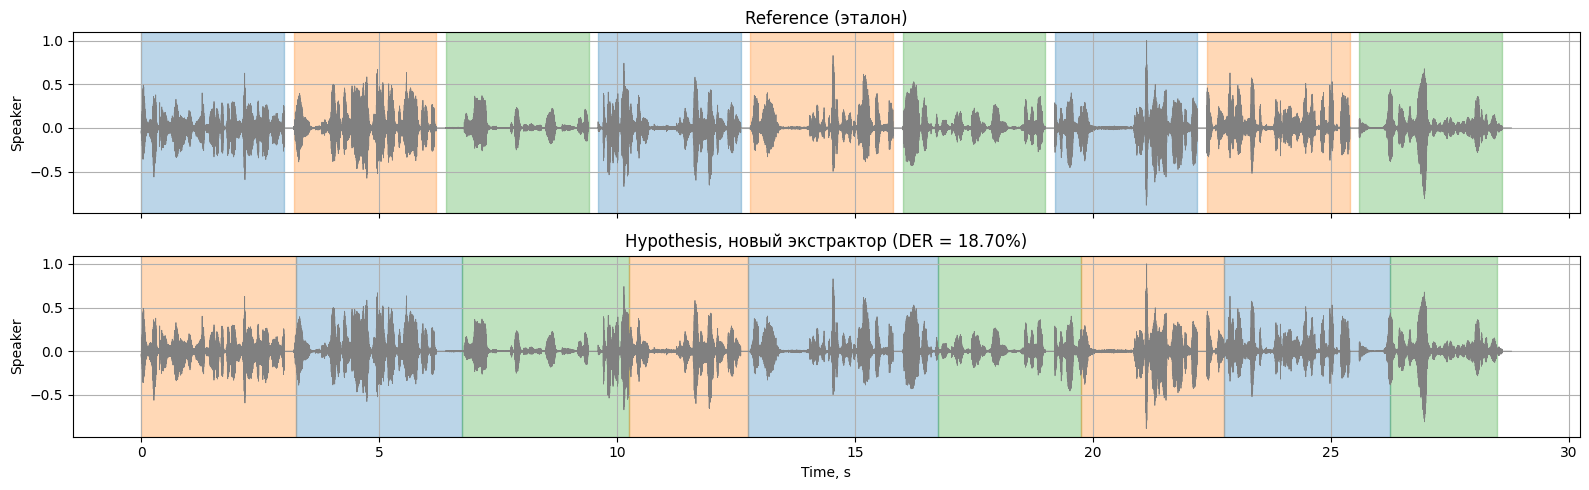

In [23]:
m1, segs_hyp1, wav1 = run_diarization(AUDIO_PATH, REF_RTTM, model)
print('Baseline (новый экстрактор) DER, %:', round(m1['der'], 2))
print('Frames:', m1['n_frames'], '| Clusters:', m1['n_clusters'])

times = np.arange(len(wav1)) / SAMPLE_RATE
colors = {idx: item for idx, item in enumerate(mcolors.TABLEAU_COLORS)}

fig, axes = plt.subplots(2, 1, figsize=(16, 5), sharex=True)

axes[0].plot(times, wav1.numpy(), color='gray', linewidth=0.6)
for s, e, lab in segments_ref:
    axes[0].axvspan(s, e, color=colors.get(lab), alpha=0.3)
axes[0].set_title('Reference (эталон)')
axes[0].set_ylabel('Speaker')
axes[0].grid(True)

axes[1].plot(times, wav1.numpy(), color='gray', linewidth=0.6)
for s, e, lab in segs_hyp1:
    axes[1].axvspan(s, e, color=colors.get(lab, 'tab:green'), alpha=0.3)
axes[1].set_title(f'Hypothesis, новый экстрактор (DER = {m1["der"]:.2f}%)')
axes[1].set_xlabel('Time, s')
axes[1].set_ylabel('Speaker')
axes[1].grid(True)

plt.tight_layout()
plt.show()

Даже с более слабым экстрактором пайплайн продолжает работать - арихитектура диаризации устойчива к качеству эмбеддингов.

**4. Контрольные вопросы**

1. Что такое дикторская диаризация?

    Дикторская диаризация - задача разделения аудиозаписи на сегменты, в каждом из которых звучит голос только одного диктора, с присвоением каждому сегменту метки говорящего. На выходе - временная разметка в форме RTTM, где указано, кто и когда говорил.

2. Как выглядит классическая схема конвейера дикторской диаризации?
   - VAD - отсев тишины и шума;
   - Сегментация - нарезка речи скользящим окном;
   - Эмбеддинги - для каждого окна нейросеть-экстрактор считает вектор-признак диктора.
   - Кластеризация - группировка эмбеддингов по дикторам;
   - Постпроцессинг - преобразование меток окон в непрерывную разметку (RTTM) и оценка DER.

3. Что такое локальные дикторские эмбеддинги?  
   Это векторы фиксированной размерности, которые экстрактор вычисляет для короткого окна. Они описывают голос диктора в этом окне. Считаются для каждого окна отдельно, а не для всей записи. Их кластеризация и лежит в основе диаризации.

4. Какие алгоритмы кластеризации вам известны и в чём отличие их использования в задаче дикторской диаризации?
   - `KMeans` минимизирует расстояния до центроидов. Нужно знать число дикторов;
   - `Agglomerative` - иерархическое слияние ближайших кластеров. Нужно число кластеров;
   - `Spectral` - строит граф сходства и режет его через собственные векторы. Хорош для невыпуклых кластеров, но критичен к affinity (у нас knn сработал, rbf - провал).
   - `DBSCAN` - плотностная кластеризация, число кластеров не задаётся. Полезен, когда число дикторов неизвестно, но требует подбора eps.

5. Как выглядит процедура формирования диаризационной разметки во временной области по результатам кластеризации локальных дикторских эмбеддингов?

   - У каждого окна есть метка (кто) и позиция (когда);
   - Склеиваем подряд идущие окна с одинаковой меткой в один сегмент;
   - Сдвигаем границы в середину перекрытия, чтобы сегменты шли встык;
   - Записываем в RTTM - получаем разметку «кто и когда говорил».